In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)




Результати класифікації:
  Метрика  Значення
 Accuracy  0.788760
Precision  0.801825
   Recall  0.766844
 F1-score  0.783944


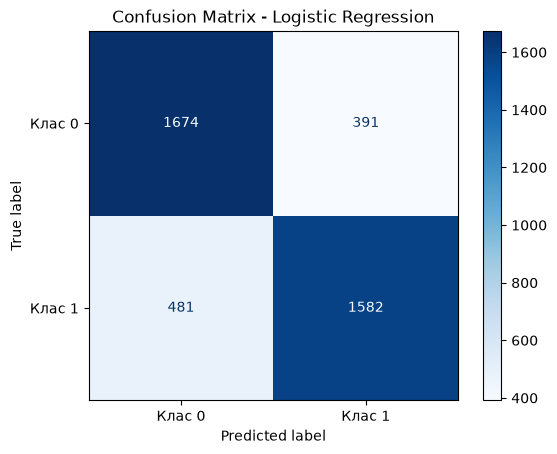

In [3]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# вхідні дані
X = df[['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms']] 

# оцінюючі дані, те що модель має передбачити
y = housing.target

median_price = np.median(y)
# перетворення числа ціни на каторії
y_class = (y > median_price).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

results = pd.DataFrame({
    'Метрика': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Значення': [
        accuracy,
        precision,
        recall,
        f1
    ]
})

print("\nРезультати класифікації:")
print(results.to_string(index=False))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Клас 0', 'Клас 1']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - Logistic Regression')
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

